# 30-Day Readmission Analysis Among Diabetic Patients
**Capstone Project 1 | Python + MySQL + Power BI**

## 1. Business problem
Hospitals want to reduce **30-day readmissions** (patients who return to hospital within 30 days of discharge). Readmissions are costly and are often a sign that a patient's care could be improved. If we know which patient and hospital-stay factors are linked to higher readmission, hospital managers know where to look first.

## 2. Business questions this notebook answers
1. What is the overall 30-day readmission rate?
2. Which factors are linked to higher readmission: prior visits, length of stay, age, diagnosis, medication change, A1C testing, admission type?
3. Can we build a simple risk grouping (High / Medium / Lower) from those factors?

## 3. Dataset
**Diabetes 130-US Hospitals for Years 1999-2008** (UCI Machine Learning Repository, licence CC BY 4.0).
- Source: https://archive.ics.uci.edu/dataset/296/diabetes-130-us-hospitals-for-years-1999-2008
- Citation: Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). DOI: https://doi.org/10.24432/C5230J
- Size: 101,766 hospital encounters, 50 columns, 130 US hospitals, 10 years.
- The raw file is **not stored in the GitHub repository**; download `diabetic_data.csv` from the link above and place it in `data/raw/`.

## 4. Workflow in this notebook
| Part | What happens | Output |
|---|---|---|
| A | Profile the raw data | Row counts, missing values, duplicates |
| B | Clean the data | 101,766 rows reduced to 69,979 patients |
| C | Validate the cleaned data | Checks that the cleaning worked |
| D | Create features | Age group, stay group, prior visits, diagnosis group, etc. |
| E | Exploratory analysis | 7 charts of readmission rate by factor |
| F | Risk grouping and verification | High / Medium / Lower risk, checked against SQL and Power BI |
| G | Load into MySQL | Table `diabetes_encounters` (optional) |

> **Privacy note:** this notebook prints only counts and summary tables. It never prints individual patient rows.

## Setup
Import the libraries and set the folder paths. The notebook can be run from the project folder or from the `notebooks` folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the project root folder (works whether Jupyter was started in the project folder or in /notebooks)
BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent

RAW_PATH = BASE / "data" / "raw" / "diabetic_data.csv"            # original download (not on GitHub)
CLEAN_PATH = BASE / "data" / "cleaned" / "diabetes_clean.csv"      # after cleaning
FEAT_PATH = BASE / "data" / "cleaned" / "diabetes_features.csv"    # after feature engineering
CHART_DIR = BASE / "charts"                                        # saved EDA charts

print("Project folder:", BASE)
print("Raw file found:", RAW_PATH.exists())

Project folder: D:\Projects\diabetes_project
Raw file found: True


## Part A: Profile the raw data
**Why:** before changing anything, we look at the size of the data, the column types, the missing values and the duplicates. Every cleaning decision in Part B comes from what we see here.

In this dataset a question mark `?` means **missing**.

In [2]:
raw = pd.read_csv(RAW_PATH, low_memory=False)

print("ROWS, COLUMNS:", raw.shape)
print("\n--- COLUMN TYPES ---")
print(raw.dtypes.to_string())

ROWS, COLUMNS: (101766, 50)

--- COLUMN TYPES ---
encounter_id                int64
patient_nbr                 int64
race                          str
gender                        str
age                           str
weight                        str
admission_type_id           int64
discharge_disposition_id    int64
admission_source_id         int64
time_in_hospital            int64
payer_code                    str
medical_specialty             str
num_lab_procedures          int64
num_procedures              int64
num_medications             int64
number_outpatient           int64
number_emergency            int64
number_inpatient            int64
diag_1                        str
diag_2                        str
diag_3                        str
number_diagnoses            int64
max_glu_serum                 str
A1Cresult                     str
metformin                     str
repaglinide                   str
nateglinide                   str
chlorpropamide                st

In [3]:
# Count the "?" (missing) values in each column. Only columns that have missing values are shown.
q = (raw == "?").sum()
print("--- '?' (MISSING) COUNT PER COLUMN ---")
print(q[q > 0].to_string())

# Percentage missing for the weight column (we will drop it in Part B)
print("\nWeight missing: {:.1f}%".format((raw["weight"] == "?").mean() * 100))

--- '?' (MISSING) COUNT PER COLUMN ---
race                  2273
weight               98569
payer_code           40256
medical_specialty    49949
diag_1                  21
diag_2                 358
diag_3                1423

Weight missing: 96.9%


In [4]:
# Duplicates: the same encounter twice, or the same patient with several encounters
print("Duplicate encounter_id:", raw["encounter_id"].duplicated().sum())
print("Repeat patients (patient_nbr appears again):", raw["patient_nbr"].duplicated().sum())

Duplicate encounter_id: 0
Repeat patients (patient_nbr appears again): 30248


In [5]:
# Value counts for key columns (counts only, no patient rows)
for col in ["readmitted", "gender", "race", "age", "A1Cresult", "max_glu_serum", "change", "diabetesMed"]:
    print(f"\n{col}")
    print(raw[col].value_counts(dropna=False).to_string())


readmitted
readmitted
NO     54864
>30    35545
<30    11357

gender
gender
Female             54708
Male               47055
Unknown/Invalid        3

race
race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641

age
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161

A1Cresult
A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812

max_glu_serum
max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264

change
change
No    54755
Ch    47011

diabetesMed
diabetesMed
Yes    78363
No     23403


In [6]:
# Summary statistics of the main numeric columns
print(raw[["time_in_hospital", "num_lab_procedures", "num_procedures",
           "num_medications", "number_diagnoses"]].describe().round(2).to_string())

       time_in_hospital  num_lab_procedures  num_procedures  num_medications  number_diagnoses
count         101766.00           101766.00       101766.00        101766.00         101766.00
mean               4.40               43.10            1.34            16.02              7.42
std                2.99               19.67            1.71             8.13              1.93
min                1.00                1.00            0.00             1.00              1.00
25%                2.00               31.00            0.00            10.00              6.00
50%                4.00               44.00            1.00            15.00              8.00
75%                6.00               57.00            2.00            20.00              9.00
max               14.00              132.00            6.00            81.00             16.00


**What we learned:** 
- There are many repeat patients, so one patient can appear in several rows. 
- `weight` is almost completely missing. 
- Some other columns (`race`, `payer_code`, `medical_specialty`, `diag_2`, `diag_3`) have missing values. 
- The target column `readmitted` has three values: `<30` (readmitted within 30 days), `>30` and `NO`.

## Part B: Clean the data
Each rule below has a reason. After every rule we record the number of rows left, so we can prove what was removed.

| Rule | Reason |
|---|---|
| Drop `weight` | 96.9% missing, too empty to use |
| Drop columns with one value in every row | They carry no information |
| Remove invalid gender | Cannot be used in gender analysis |
| Remove patients who died or went to hospice | They cannot be readmitted, so they would distort the rate |
| Remove rows with no primary diagnosis | We group patients by diagnosis |
| Fill other missing values with "Unknown" | Keeps the rows without guessing a value |
| Treat "None" in test columns as "Not Tested" | "None" means the test was not done, not that data is missing |
| Keep only the first encounter per patient | Each patient counts once, so frequent patients do not dominate |

In [7]:
# "?" means missing. "None" is real text (test not done), so we keep it as text.
df = pd.read_csv(RAW_PATH, na_values="?", keep_default_na=False, low_memory=False)

steps = [("Start (raw data)", len(df))]     # we record the row count after each rule
print(f"Start: {len(df)} rows, {df.shape[1]} columns")

Start: 101766 rows, 50 columns


In [8]:
# Rule 1: drop the weight column (96.9% missing)
df = df.drop(columns=["weight"])

# Rule 2: drop columns that have the same value in every row
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
df = df.drop(columns=const_cols)
print("Dropped constant columns:", const_cols)

Dropped constant columns: ['examide', 'citoglipton']


In [9]:
# Rule 3: remove rows with invalid gender
df = df[df["gender"] != "Unknown/Invalid"]
steps.append(("Removed invalid gender", len(df)))

# Rule 4: remove patients who died or went to hospice (they cannot be readmitted)
# discharge_disposition_id codes: 11 = expired, 13 and 14 = hospice, 19, 20, 21 = expired (other settings)
df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]
steps.append(("Removed died / hospice", len(df)))

# Rule 5: remove rows with no primary diagnosis
df = df.dropna(subset=["diag_1"])
steps.append(("Removed missing primary diagnosis", len(df)))

In [10]:
# Rule 6: fill the remaining missing values with "Unknown"
for col in ["race", "payer_code", "medical_specialty", "diag_2", "diag_3"]:
    df[col] = df[col].fillna("Unknown")

# Rule 7: "None" in the test columns means the test was not done
for col in ["A1Cresult", "max_glu_serum"]:
    df[col] = df[col].replace("None", "Not Tested")

# Rule 8: keep only the first encounter for each patient
df = df.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")
steps.append(("Kept first encounter per patient", len(df)))

In [11]:
# Row reconciliation table: how many rows each rule removed
recon = pd.DataFrame(steps, columns=["Step", "Rows left"])
recon["Rows removed"] = (recon["Rows left"].shift(1) - recon["Rows left"]).fillna(0).astype(int)
print(recon.to_string(index=False))
print("\nTotal removed:", int(recon["Rows removed"].sum()))

                             Step  Rows left  Rows removed
                 Start (raw data)     101766             0
           Removed invalid gender     101763             3
           Removed died / hospice      99340          2423
Removed missing primary diagnosis      99320            20
 Kept first encounter per patient      69979         29341

Total removed: 31787


**Reading the table:** the rule "keep the first encounter per patient" removed by far the most rows. These were repeat visits by the same patients, not bad data. After this step every row is one **patient**.

## Part C: Validate the cleaned data
We check that the cleaning really worked. If any check fails, the cell stops with an error.

In [12]:
# Check 1: every patient appears only once
assert df["patient_nbr"].is_unique, "Some patients appear more than once"

# Check 2: no missing values are left
assert df.isna().sum().sum() == 0, "Missing values are still present"

# Check 3: no invalid gender is left
assert (df["gender"] == "Unknown/Invalid").sum() == 0

# Check 4: no died / hospice patients are left
assert not df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21]).any()

# Check 5: the target column only has the three expected values
assert set(df["readmitted"].unique()) == {"<30", ">30", "NO"}

print("All 5 validation checks passed.")
print("\nFINAL SHAPE:", df.shape)
print("Missing values left:", int(df.isna().sum().sum()))

All 5 validation checks passed.

FINAL SHAPE: (69979, 47)
Missing values left: 0


In [13]:
# Summary of the cleaned data (counts only)
print("readmitted counts:")
print(df["readmitted"].value_counts().to_string())

rate = (df["readmitted"] == "<30").mean() * 100
print(f"\n30-day readmission rate: {rate:.2f}%")

print("\nA1Cresult counts:")
print(df["A1Cresult"].value_counts().to_string())

readmitted counts:
readmitted
NO     41472
>30    22224
<30     6283

30-day readmission rate: 8.98%

A1Cresult counts:
A1Cresult
Not Tested    57136
>8             6237
Norm           3740
>7             2866


In [14]:
# Save the cleaned data for the next parts (this file stays on your computer, not on GitHub)
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN_PATH, index=False)
print("Saved to:", CLEAN_PATH)

Saved to: D:\Projects\diabetes_project\data\cleaned\diabetes_clean.csv


## Part D: Create features
**Why:** raw columns such as exact age or exact number of days are hard to compare. Grouping them makes patterns easy to read in charts, SQL and Power BI.

| New column | How it is made |
|---|---|
| `readmitted_30` | 1 if readmitted within 30 days (`<30`), otherwise 0. This is our target. |
| `age_group` | 10-year bands grouped into 0-29, 30-59, 60-79, 80+ |
| `stay_group` | Short (1-3 days), Medium (4-7 days), Long (8+ days) |
| `meds_active` | Number of diabetes medicines the patient is on |
| `meds_changed` | Number of medicines whose dose was changed up or down |
| `prior_visits` | Outpatient + emergency + inpatient visits in the previous year |
| `diag_group` | Primary diagnosis grouped from ICD-9 codes (Circulatory, Respiratory, Injury, ...) |
| `admission_type` | Readable name for the admission type code |

In [15]:
feat = pd.read_csv(CLEAN_PATH, low_memory=False)

# 1. Target flag: 1 = readmitted within 30 days
feat["readmitted_30"] = (feat["readmitted"] == "<30").astype(int)

# 2. Age group
age_map = {
    "[0-10)": "0-29", "[10-20)": "0-29", "[20-30)": "0-29",
    "[30-40)": "30-59", "[40-50)": "30-59", "[50-60)": "30-59",
    "[60-70)": "60-79", "[70-80)": "60-79",
    "[80-90)": "80+", "[90-100)": "80+",
}
feat["age_group"] = feat["age"].map(age_map)

# 3. Length of stay group (1-3, 4-7, 8+ days)
feat["stay_group"] = pd.cut(
    feat["time_in_hospital"],
    bins=[0, 3, 7, 100],
    labels=["Short (1-3 days)", "Medium (4-7 days)", "Long (8+ days)"],
)

In [16]:
# 4. Medication counts
med_cols = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone",
    "metformin-pioglitazone",
]
feat["meds_active"] = (feat[med_cols] != "No").sum(axis=1)               # medicines the patient takes
feat["meds_changed"] = feat[med_cols].isin(["Up", "Down"]).sum(axis=1)   # medicines with a dose change

# 5. Prior visits in the previous year
feat["prior_visits"] = (
    feat["number_outpatient"] + feat["number_emergency"] + feat["number_inpatient"]
)

In [17]:
# 6. Primary diagnosis group from the ICD-9 code
def diag_group(code):
    code = str(code)
    if code.startswith(("V", "E")):
        return "Other"
    try:
        n = float(code)
    except ValueError:
        return "Other"
    if 250 <= n < 251:
        return "Diabetes"
    if 390 <= n <= 459 or n == 785:
        return "Circulatory"
    if 460 <= n <= 519 or n == 786:
        return "Respiratory"
    if 520 <= n <= 579 or n == 787:
        return "Digestive"
    if 800 <= n <= 999:
        return "Injury"
    if 710 <= n <= 739:
        return "Musculoskeletal"
    if 580 <= n <= 629 or n == 788:
        return "Genitourinary"
    if 140 <= n <= 239:
        return "Neoplasms"
    return "Other"

feat["diag_group"] = feat["diag_1"].apply(diag_group)

# 7. Admission type name
adm_map = {1: "Emergency", 2: "Urgent", 3: "Elective"}
feat["admission_type"] = feat["admission_type_id"].map(adm_map).fillna("Other/Unknown")

In [18]:
# Save the feature file (stays on your computer, not on GitHub)
feat.to_csv(FEAT_PATH, index=False)

print("FINAL SHAPE:", feat.shape)
print("\nreadmitted_30 counts:")
print(feat["readmitted_30"].value_counts().to_string())

for col in ["age_group", "stay_group", "diag_group", "admission_type"]:
    print(f"\n{col} counts:")
    print(feat[col].value_counts().to_string())

FINAL SHAPE: (69979, 55)

readmitted_30 counts:
readmitted_30
0    63696
1     6283

age_group counts:
age_group
60-79    33433
30-59    21869
80+      12869
0-29      1808

stay_group counts:
stay_group
Short (1-3 days)     35139
Medium (4-7 days)    25073
Long (8+ days)        9767

diag_group counts:
diag_group
Circulatory        21391
Other              12124
Respiratory         9491
Digestive           6488
Diabetes            5748
Injury              4694
Musculoskeletal     4064
Genitourinary       3441
Neoplasms           2538

admission_type counts:
admission_type
Emergency        35475
Elective         13782
Urgent           12803
Other/Unknown     7919


In [19]:
print("meds_active / meds_changed / prior_visits summary:")
print(feat[["meds_active", "meds_changed", "prior_visits"]].describe().round(2).to_string())

print("\n30-day readmission rate by age_group (%):")
print((feat.groupby("age_group")["readmitted_30"].mean() * 100).round(2).to_string())
print("\nSaved to:", FEAT_PATH)

meds_active / meds_changed / prior_visits summary:
       meds_active  meds_changed  prior_visits
count     69979.00      69979.00      69979.00
mean          1.19          0.26          0.56
std           0.94          0.48          1.43
min           0.00          0.00          0.00
25%           1.00          0.00          0.00
50%           1.00          0.00          0.00
75%           2.00          0.00          1.00
max           6.00          4.00         49.00

30-day readmission rate by age_group (%):
age_group
0-29      6.19
30-59     7.19
60-79     9.66
80+      10.62

Saved to: D:\Projects\diabetes_project\data\cleaned\diabetes_features.csv


## Part E: Exploratory analysis
**Why:** we compare the 30-day readmission rate across groups to see which factors matter. The red dashed line on each chart is the overall rate. A bar above the line means that group has a higher readmission rate than average.

The charts are shown here and also saved in the `charts` folder.

Overall 30-day readmission rate: 8.98%

Age group
           patients   rate
age_group                 
0-29           1808   6.19
30-59         21869   7.19
60-79         33433   9.66
80+           12869  10.62


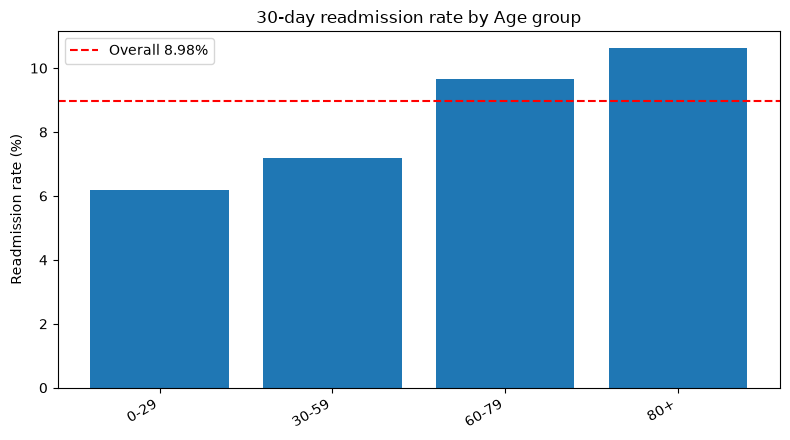


Length of stay
                   patients   rate
stay_group                        
Short (1-3 days)      35139   7.53
Medium (4-7 days)     25073   9.91
Long (8+ days)         9767  11.79


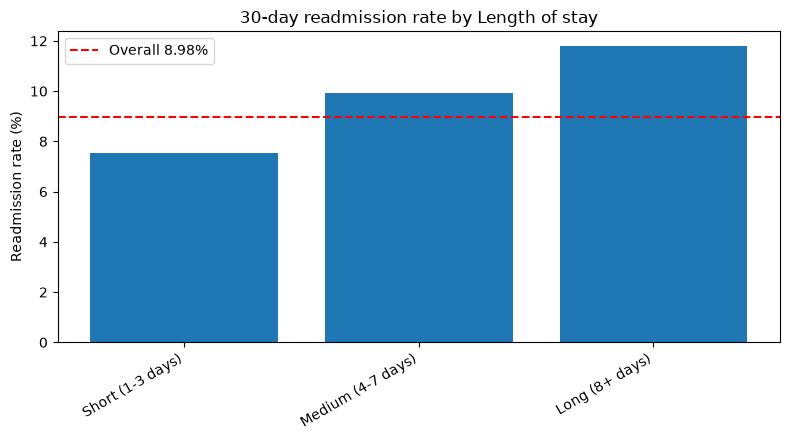


Prior visits (last year)
                    patients   rate
prior_visits_group                 
0                      51773   7.94
1-2                    13498  11.07
3-5                     3780  13.47
6+                       928  18.00


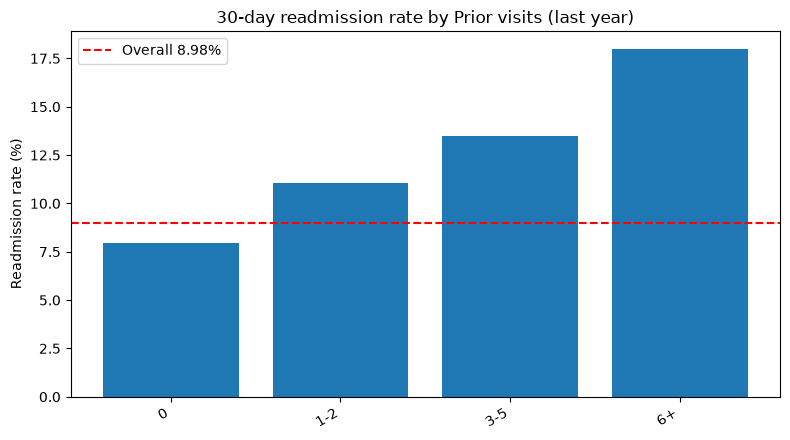


Primary diagnosis
                 patients   rate
diag_group                      
Injury               4694  10.80
Circulatory         21391   9.68
Diabetes             5748   9.12
Neoplasms            2538   9.06
Genitourinary        3441   8.98
Other               12124   8.98
Musculoskeletal      4064   8.39
Digestive            6488   8.01
Respiratory          9491   7.30


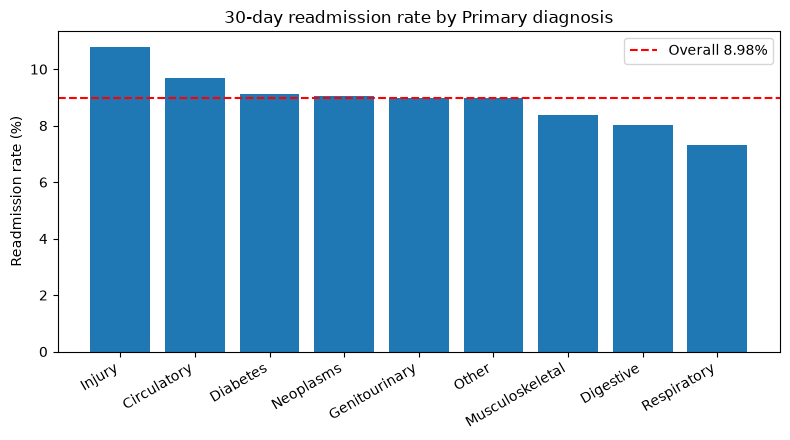


A1C result
            patients  rate
A1Cresult                 
Not Tested     57136  9.11
>7              2866  8.62
Norm            3740  8.61
>8              6237  8.16


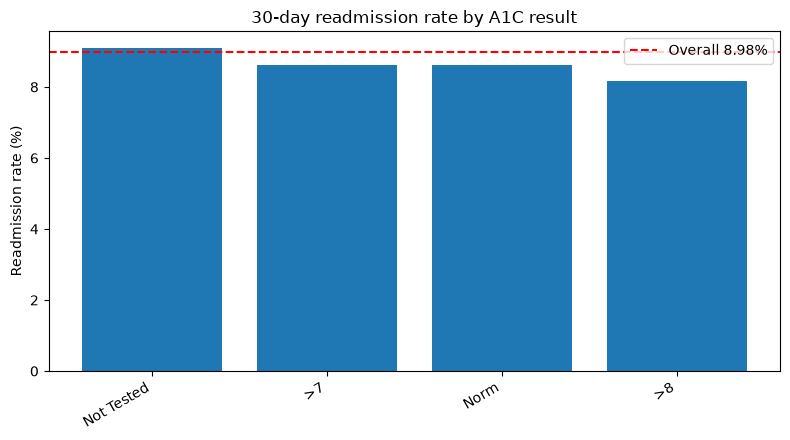


Medication change
        patients  rate
change                
Ch         31490  9.44
No         38489  8.60


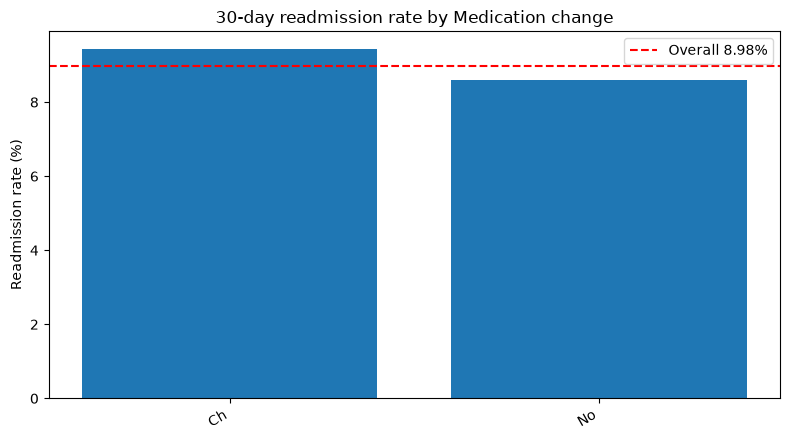


Admission type
                patients  rate
admission_type                
Other/Unknown       7919  9.29
Emergency          35475  9.18
Urgent             12803  8.97
Elective           13782  8.29


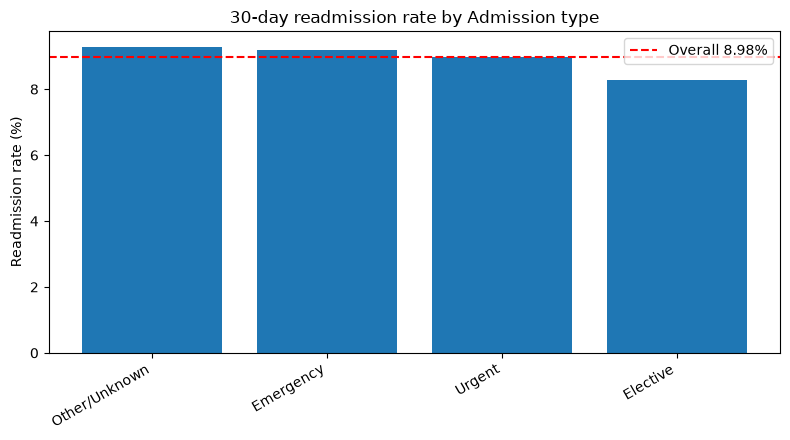


Charts saved to: D:\Projects\diabetes_project\charts


In [20]:
CHART_DIR.mkdir(exist_ok=True)

overall = feat["readmitted_30"].mean() * 100
print(f"Overall 30-day readmission rate: {overall:.2f}%")

# Group prior visits: 0, 1-2, 3-5, 6+
feat["prior_visits_group"] = pd.cut(
    feat["prior_visits"], bins=[-1, 0, 2, 5, 100], labels=["0", "1-2", "3-5", "6+"]
)

factors = {
    "age_group": "Age group",
    "stay_group": "Length of stay",
    "prior_visits_group": "Prior visits (last year)",
    "diag_group": "Primary diagnosis",
    "A1Cresult": "A1C result",
    "change": "Medication change",
    "admission_type": "Admission type",
}
sort_by_rate = ["diag_group", "A1Cresult", "change", "admission_type"]   # sort these from highest to lowest

for col, title in factors.items():
    g = feat.groupby(col, observed=True)["readmitted_30"].agg(patients="count", rate="mean")
    g["rate"] = (g["rate"] * 100).round(2)
    if col in sort_by_rate:
        g = g.sort_values("rate", ascending=False)

    print(f"\n{title}")
    print(g.to_string())

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(g.index.astype(str), g["rate"])
    ax.axhline(overall, linestyle="--", color="red", label=f"Overall {overall:.2f}%")
    ax.set_title(f"30-day readmission rate by {title}")
    ax.set_ylabel("Readmission rate (%)")
    ax.legend()
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    fig.savefig(CHART_DIR / f"readmission_by_{col}.png", dpi=150)
    plt.show()

print("\nCharts saved to:", CHART_DIR)

**What the charts show:**
- **Prior visits** is the strongest factor: the rate rises steadily as the number of prior visits rises.
- **Length of stay** and **age** also show a clear rise.
- **Primary diagnosis** matters: Injury is highest and Respiratory is lowest.
- **Medication change** and **admission type** show only small differences.
- Most patients (about 82%) had **no A1C test**, and that group had the highest rate among the A1C groups.

These are **associations, not causes**.

## Part F: Risk grouping and verification
**Why:** managers need a simple way to spot patients who need extra attention. We combine the two strongest factors, prior visits and length of stay, into three groups:

| Risk group | Rule |
|---|---|
| High risk | 3 or more prior visits **and** a stay of 8 or more days |
| Medium risk | Only one of the two |
| Lower risk | Neither |

This is a **rule-based grouping, not a prediction model**.

In [21]:
many_visits = feat["prior_visits"] >= 3          # 3+ prior visits
long_stay = feat["time_in_hospital"] >= 8        # 8+ days in hospital

def risk_segment(v, s):
    if v and s:
        return "1 - High risk"
    if v or s:
        return "2 - Medium risk"
    return "3 - Lower risk"

feat["risk_segment"] = [risk_segment(v, s) for v, s in zip(many_visits, long_stay)]

seg = feat.groupby("risk_segment")["readmitted_30"].agg(patients="count", readmitted="sum", rate="mean")
seg["rate"] = (seg["rate"] * 100).round(2)
print(seg.to_string())

                 patients  readmitted   rate
risk_segment                                
1 - High risk         683         119  17.42
2 - Medium risk     13109        1590  12.13
3 - Lower risk      56187        4574   8.14


In [22]:
# Matrix: readmission rate by prior visits group and length of stay (%)
matrix = (feat.pivot_table(index="prior_visits_group", columns="stay_group",
                           values="readmitted_30", aggfunc="mean", observed=True) * 100).round(2)
print(matrix.to_string())

stay_group          Short (1-3 days)  Medium (4-7 days)  Long (8+ days)
prior_visits_group                                                     
0                               6.52               8.86           10.82
1-2                             9.54              12.22           13.35
3-5                            12.22              14.30           15.58
6+                             17.25              16.22           25.19


### Verification against SQL and Power BI
The numbers below were also produced by the 9 SQL queries and shown in the Power BI dashboard. The check compares this notebook with those values.

In [23]:
expected = {
    "Total patients": (len(feat), 69979),
    "Readmitted within 30 days": (int(feat["readmitted_30"].sum()), 6283),
    "Overall rate (%)": (round(overall, 2), 8.98),
    "High risk patients": (int(seg.loc["1 - High risk", "patients"]), 683),
    "High risk rate (%)": (float(seg.loc["1 - High risk", "rate"]), 17.42),
    "Medium risk rate (%)": (float(seg.loc["2 - Medium risk", "rate"]), 12.13),
    "Lower risk rate (%)": (float(seg.loc["3 - Lower risk", "rate"]), 8.14),
}
check = pd.DataFrame(
    [(k, a, b, "OK" if abs(a - b) < 0.005 else "CHECK") for k, (a, b) in expected.items()],
    columns=["Measure", "This notebook", "SQL / Power BI", "Result"],
)
print(check.to_string(index=False))

                  Measure  This notebook  SQL / Power BI Result
           Total patients       69979.00        69979.00     OK
Readmitted within 30 days        6283.00         6283.00     OK
         Overall rate (%)           8.98            8.98     OK
       High risk patients         683.00          683.00     OK
       High risk rate (%)          17.42           17.42     OK
     Medium risk rate (%)          12.13           12.13     OK
      Lower risk rate (%)           8.14            8.14     OK


## Part G: Load the data into MySQL (optional)
**Why:** MySQL stores the cleaned data so that SQL queries and Power BI use the same table. The password is typed when the cell runs, so it is **never saved in the code**.

Before running this part:
1. MySQL must be running and the database `diabetes_db` must exist.
2. The table `diabetes_encounters` must exist (create it with `sql/00_schema.sql`).
3. Install the libraries once: `pip install sqlalchemy pymysql`.

Skip this part if you only want to review the analysis.

In [ ]:
import getpass
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text, inspect

# ---------- Settings ----------
DB_USER = "diabetes_user"
DB_PASS = quote_plus(getpass.getpass("MySQL password for diabetes_user: "))   # typed at run time, never saved
DB_HOST = "localhost"
DB_PORT = 3306
DB_NAME = "diabetes_db"
TABLE = "diabetes_encounters"

engine = create_engine(f"mysql+pymysql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

# ---------- 1. Read the feature file ----------
# keep_default_na=False stops pandas from turning text like "None" or "NA" into empty values
to_load = pd.read_csv(FEAT_PATH, keep_default_na=False, low_memory=False)
print("Rows read from CSV:", len(to_load), "| Columns:", to_load.shape[1])

In [ ]:
# ---------- 2. Empty the table first (so the cell is safe to run again) ----------
if inspect(engine).has_table(TABLE):
    with engine.begin() as conn:
        conn.execute(text(f"TRUNCATE TABLE {TABLE}"))

# ---------- 3. Load the data into MySQL ----------
to_load.to_sql(TABLE, engine, if_exists="append", index=False, chunksize=2000, method="multi")
print("Load finished")

# ---------- 4. Check the result ----------
with engine.connect() as conn:
    n = conn.execute(text(f"SELECT COUNT(*) FROM {TABLE}")).scalar()
    r = conn.execute(text(f"SELECT ROUND(AVG(readmitted_30) * 100, 2) FROM {TABLE}")).scalar()
print("Rows in MySQL:", n)
print("30-day readmission rate (%):", r)

## Summary of findings
- Overall, **8.98%** of patients (6,283 of 69,979) were readmitted within 30 days.
- **Prior visits** is the strongest factor: 7.94% with no prior visits, rising to 18.00% with 6 or more.
- Longer stays and older age are also linked to higher readmission (7.53% to 11.79% by stay, 6.19% to 10.62% by age).
- The **High risk** group (3+ prior visits and 8+ days) has a 17.42% rate, compared with 8.14% for the Lower risk group.
- Most patients (81.65%) had no A1C test, so conclusions about A1C are limited.

## Limitations
- The results show **associations, not causes**.
- The risk groups are simple rules, not a validated prediction model.
- Only each patient's **first** encounter is kept, so the results describe first stays.
- The High risk group is small (683 patients, about 1% of the data).